# Evaluate segmentation results

Compare saved PanopTILs predictions with the matching validation labels. Measure
how well nuclei are detected, how closely their masks overlap, and which cell
types need improvement. Evaluation runs on CPU; it does not rerun the model.

The example model was trained for only five epochs and is still undertrained.
Its low scores, especially for some cell types, demonstrate how to compute and
interpret the metrics. They are not a benchmark of fully trained models.

Use the masks saved by [image inference](inference.ipynb). Keep one `.npz` file
per image in `predictions/`, named after the source image, with `instances` and
`classes` arrays. The example outputs use 16 held-out validation regions.


## Setup


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Patch
from skimage.color import label2rgb
from skimage.segmentation import find_boundaries

from cellseg_models_pytorch.metrics import (
    dice_coef,
    get_stats,
    iou_score,
    panoptic_quality,
)
from cellseg_models_pytorch.utils import FileHandler

data_root = Path("../../data/panoptils-nuclei")
prediction_root = Path("predictions")
example_images = ["region_1252", "region_0804"]
class_names = [
    "untyped",
    "neoplastic",
    "stromal",
    "inflammatory",
    "epithelial",
    "other",
    "unknown",
]

# Use the same class colours in reference and prediction overlays.
class_palette = np.array(
    [
        [0.55, 0.3, 0.15],
        [0.9, 0.2, 0.2],
        [0.2, 0.5, 0.9],
        [0.2, 0.75, 0.3],
        [0.8, 0.3, 0.8],
        [0.95, 0.7, 0.15],
        [0.6, 0.6, 0.6],
    ],
    dtype=np.float32,
)

# Keep every score column and the 16 image rows visible in the tables.
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_rows(20)


def load_prediction(path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Read the saved instance and cell-type masks for one image."""
    with np.load(path, allow_pickle=False) as saved:
        return saved["instances"], saved["classes"]


## Load matching masks

Instance masks are integer arrays with shape `(height, width)`: zero is background
and each positive ID identifies one nucleus. IDs need not match between reference
and prediction. Cell-type masks assign a category to each nucleus.

Both masks must cover the same pixels at the same resolution. No normalization
or resizing is needed for evaluation. PanopTILs class 0 can contain untyped
nuclei, so use the **instance mask**, rather than the class mask, to find foreground.


## Compute the scores

Panoptic quality (**PQ**) combines two scores:

- **Detection quality (DQ)** measures missed and extra nuclei using object F1.
- **Segmentation quality (SQ)** is the mean intersection over union (IoU) of
  matched nuclei. IoU measures their shared area divided by their combined area.

`PQ = DQ × SQ`. Scores approach 1 for a perfect result. With `thresh=0.5`, a
reference nucleus matches a prediction only when their IoU is **greater than**
0.5. Each nucleus can match at most one other nucleus.

Binary Dice and IoU compare the pixels covered by any nucleus. Merging two nuclei
can leave foreground coverage unchanged, so use these scores alongside PQ.

The function below evaluates one mask pair and returns one table row. Pairs with
no nuclei on either side receive null scores, which are excluded from averages.
An empty mask paired with a nonempty mask scores zero.


In [2]:
def score_masks(reference: np.ndarray, prediction: np.ndarray) -> pl.DataFrame:
    """Return nucleus counts and instance/foreground scores for one mask pair."""
    quality = panoptic_quality(reference, prediction, thresh=0.5)
    tp, fp, fn = get_stats(
        (reference > 0).astype(np.uint8),
        (prediction > 0).astype(np.uint8),
    )
    result = pl.DataFrame(
        {
            "Reference nuclei": [np.count_nonzero(np.unique(reference))],
            "Predicted nuclei": [np.count_nonzero(np.unique(prediction))],
            "PQ": [quality["pq"]],
            "DQ": [quality["dq"]],
            "SQ": [quality["sq"]],
            "Dice": [dice_coef(tp, fp, fn)],
            "IoU": [iou_score(tp, fp, fn)],
        }
    )

    # Keep scores undefined only when neither mask contains a nucleus.
    return result.with_columns(
        pl.when(pl.col("Reference nuclei") + pl.col("Predicted nuclei") > 0)
        .then(pl.col("PQ", "DQ", "SQ", "Dice", "IoU"))
        .otherwise(None)
    )


## Evaluate the saved predictions

Read each prediction and its matching labels once. First score all nuclei,
including untyped ones, then score each cell type separately. The metric functions
work on NumPy masks; Polars collects and summarizes their scores. Only small score
tables are kept in memory between images.


In [3]:
prediction_paths = sorted(prediction_root.glob("*.npz"))
tables = []

for path in prediction_paths:
    reference = FileHandler.read_mat(
        data_root / "validation/regions/labels" / f"{path.stem}.mat"
    )
    instances, classes = load_prediction(path)

    per_type = [
        score_masks(reference["inst"], instances).with_columns(
            pl.lit("all nuclei").alias("Cell type")
        )
    ]
    for class_id, name in enumerate(class_names[1:], start=1):
        # Keep original nucleus IDs while selecting one cell type.
        true_class = np.where(reference["type"] == class_id, reference["inst"], 0)
        predicted_class = np.where(classes == class_id, instances, 0)
        per_type.append(
            score_masks(true_class, predicted_class).with_columns(
                pl.lit(name).alias("Cell type")
            )
        )

    tables.append(pl.concat(per_type).with_columns(pl.lit(path.stem).alias("Image")))

scores = pl.concat(tables).select(
    "Image", "Cell type", pl.exclude("Image", "Cell type")
)
image_scores = scores.filter(pl.col("Cell type") == "all nuclei").drop("Cell type")
image_scores.with_columns(pl.col(pl.Float64).round(3))


Image,Reference nuclei,Predicted nuclei,PQ,DQ,SQ,Dice,IoU
str,i64,i64,f64,f64,f64,f64,f64
"""region_0000""",568,623,0.686,0.883,0.777,0.851,0.741
"""region_0331""",402,457,0.605,0.78,0.776,0.81,0.68
"""region_0386""",274,208,0.594,0.759,0.783,0.81,0.681
"""region_0401""",367,317,0.631,0.822,0.768,0.82,0.695
"""region_0555""",422,426,0.625,0.823,0.76,0.828,0.706
"""region_0604""",587,593,0.659,0.846,0.78,0.857,0.75
"""region_0658""",452,471,0.596,0.821,0.726,0.838,0.721
"""region_0690""",348,365,0.5,0.662,0.755,0.771,0.627
"""region_0804""",487,634,0.564,0.737,0.765,0.732,0.577


## Inspect the masks

Check the alignment before interpreting scores. Different colours distinguish
individual nuclei; their colours do not need to match across panels.

Each row shows one example region. The single-image tables below use the first
region; the cell-type comparison evaluates both.


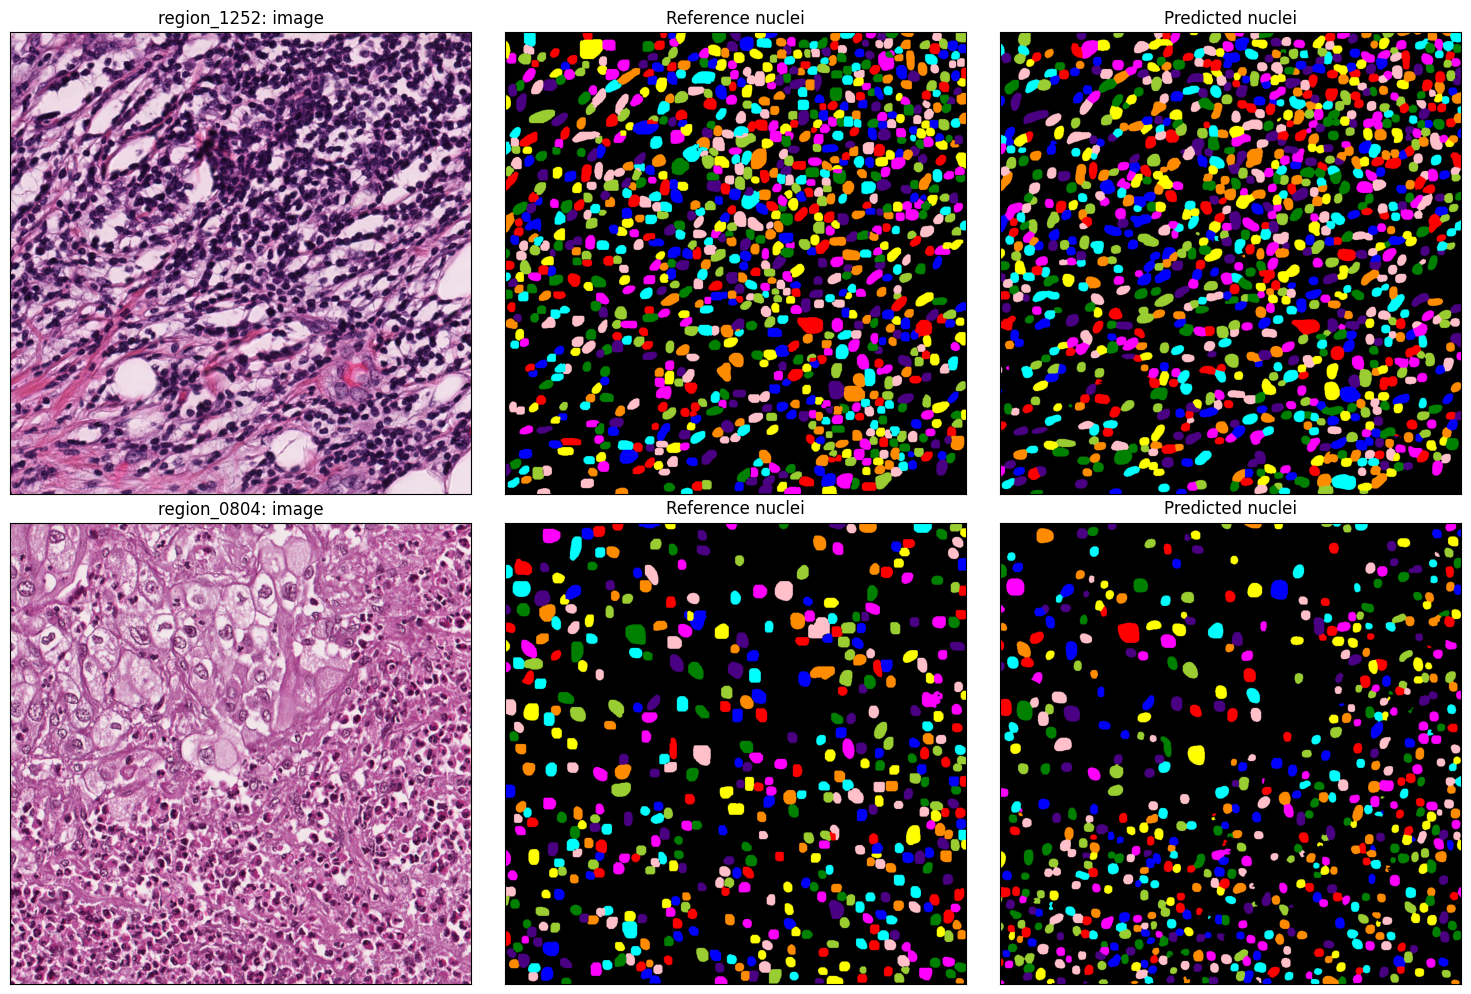

In [4]:
fig, axes = plt.subplots(
    len(example_images), 3, figsize=(15, 5 * len(example_images)), squeeze=False
)

for row, name in enumerate(example_images):
    image_path = data_root / "validation/regions/images" / f"{name}.png"
    region_image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    reference = FileHandler.read_mat(
        data_root / "validation/regions/labels" / f"{name}.mat"
    )
    instances, _ = load_prediction(prediction_root / f"{name}.npz")

    axes[row, 0].imshow(region_image)
    axes[row, 0].set_title(f"{name}: image")

    axes[row, 1].imshow(label2rgb(reference["inst"], bg_label=0))
    axes[row, 1].set_title("Reference nuclei")

    axes[row, 2].imshow(label2rgb(instances, bg_label=0))
    axes[row, 2].set_title("Predicted nuclei")

for axis in axes.flat:
    axis.set(xticks=[], yticks=[])

fig.tight_layout()
plt.show()


## Inspect the first region's scores

Select the first illustrated region from the score table. These instance scores
evaluate nuclei regardless of cell type. The counts help distinguish missed or
extra nuclei from inaccurate boundaries.


In [5]:
first_region = image_scores.filter(pl.col("Image") == example_images[0])
quality = first_region.select("Reference nuclei", "Predicted nuclei", "PQ", "DQ", "SQ")
quality.with_columns(pl.col(pl.Float64).round(3))


Reference nuclei,Predicted nuclei,PQ,DQ,SQ
i64,i64,f64,f64,f64
1039,1087,0.711,0.907,0.784


### Foreground coverage

Use the same row to inspect Dice and IoU. High foreground overlap can coexist
with poor PQ when touching nuclei are merged or individual nuclei are split.


In [6]:
foreground = first_region.select("Dice", "IoU")
foreground.with_columns(pl.col(pl.Float64).round(3))


Dice,IoU
f64,f64
0.879,0.784


## Evaluate cell types

Compute PQ separately for each category using the same class mapping for labels
and predictions. A correctly located nucleus with the wrong type becomes a missed
nucleus for its reference class and an extra nucleus for its predicted class.

Untyped class 0 nuclei remain in the all-nuclei scores above, but are excluded
from the per-type table. The dataset's explicit “unknown” category is still shown.
`null` means neither the reference nor the prediction contains nuclei of that
category. There is no score to evaluate, so the entry is excluded from averages.
If nuclei appear on only one side, the score is 0: they were missed or added.
In summary tables, `null` means no evaluated image had that category on either side.

Predictions assigned a typed category over an untyped reference nucleus still
count as extras in that category; this example does not exclude untyped regions from scoring.


In [7]:
class_scores = (
    pl.DataFrame({"Image": example_images})
    .join(
        scores.filter(pl.col("Cell type") != "all nuclei"),
        on="Image",
        how="left",
        maintain_order="left",
    )
    .select(
        "Image", "Cell type", "Reference nuclei", "Predicted nuclei", "PQ", "DQ", "SQ"
    )
)
class_scores.with_columns(pl.col(pl.Float64).round(3))


Image,Cell type,Reference nuclei,Predicted nuclei,PQ,DQ,SQ
str,str,i64,i64,f64,f64,f64
"""region_1252""","""neoplastic""",0,0,null,null,null
"""region_1252""","""stromal""",309,358,0.493,0.654,0.754
"""region_1252""","""inflammatory""",725,729,0.658,0.825,0.798
"""region_1252""","""epithelial""",0,0,null,null,null
"""region_1252""","""other""",0,0,null,null,null
"""region_1252""","""unknown""",1,0,0.0,0.0,0.0
"""region_0804""","""neoplastic""",125,90,0.498,0.651,0.766
"""region_0804""","""stromal""",164,51,0.158,0.214,0.739
"""region_0804""","""inflammatory""",193,38,0.216,0.268,0.806


### Compare cell-type overlays

Compare the reference and predicted nuclei on the same tissue image. Coloured
outlines mark individual nuclei, and a light fill shows their cell types while
keeping the tissue visible. Blue is stromal and green is inflammatory; the legend
shows all categories. Background tissue keeps its original colour.


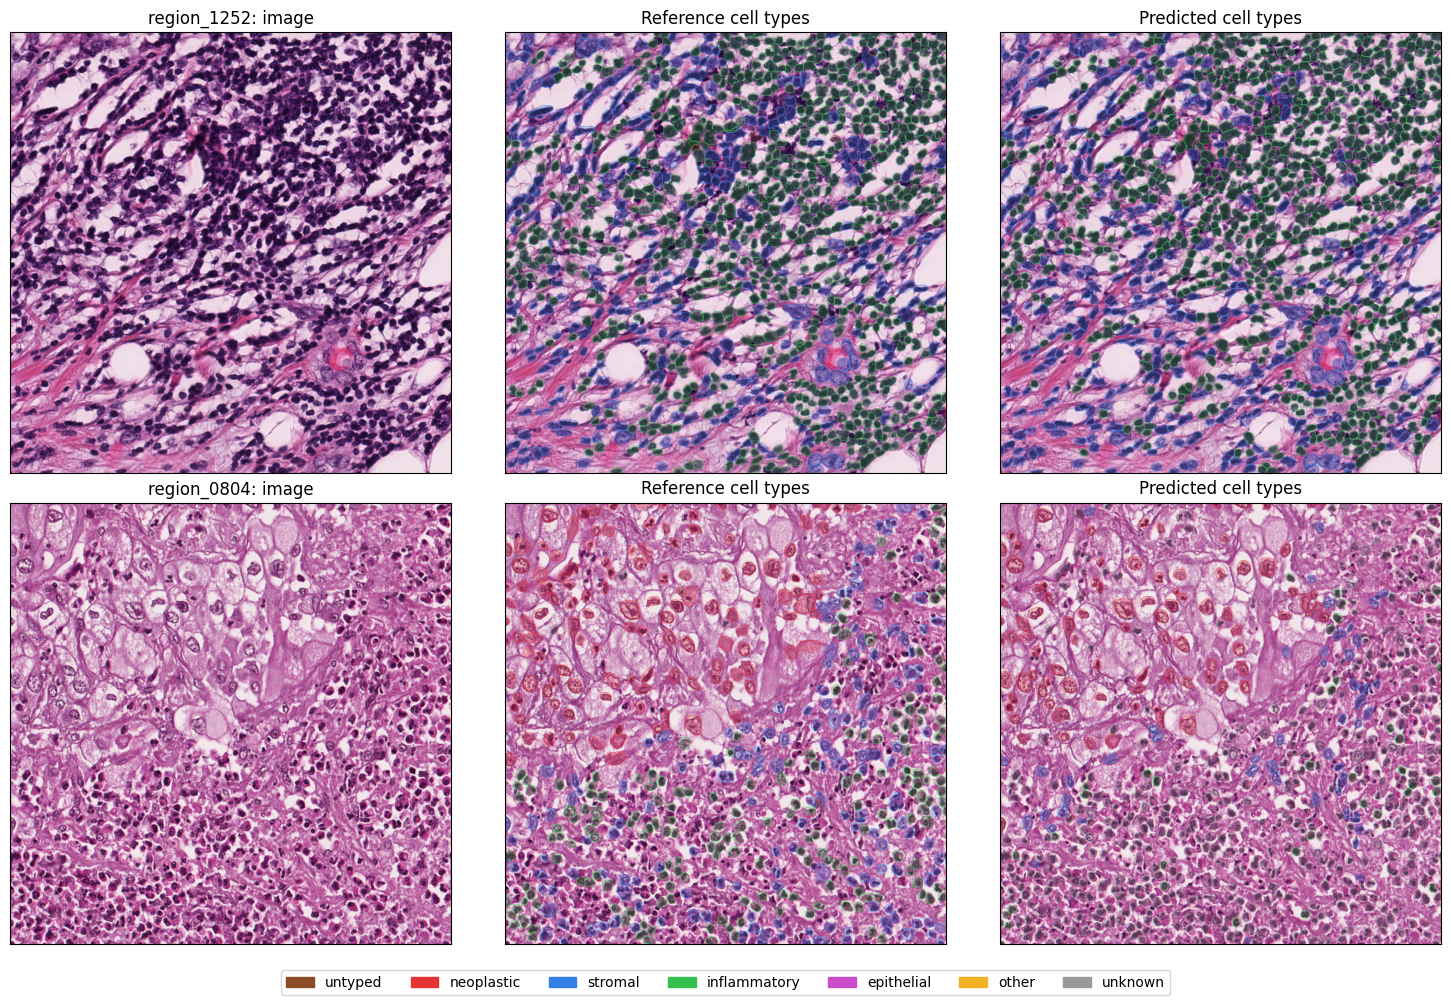

In [8]:
def cell_type_overlay(
    image: np.ndarray, instances: np.ndarray, classes: np.ndarray
) -> np.ndarray:
    """Overlay cell types and nucleus outlines on a uint8 RGB image.

    Returns an RGB float32 image in [0, 1], leaving background tissue unchanged.
    """
    overlay = image.astype(np.float32) / 255
    colours = class_palette[classes]
    foreground = instances > 0

    # A light fill keeps the tissue visible; outlines separate touching nuclei.
    overlay[foreground] = 0.75 * overlay[foreground] + 0.25 * colours[foreground]
    outlines = find_boundaries(instances, mode="inner")
    overlay[outlines] = colours[outlines]
    return overlay


overlay_fig, overlay_axes = plt.subplots(
    len(example_images), 3, figsize=(15, 5 * len(example_images)), squeeze=False
)

for row, name in enumerate(example_images):
    image_path = data_root / "validation/regions/images" / f"{name}.png"
    region_image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    reference = FileHandler.read_mat(
        data_root / "validation/regions/labels" / f"{name}.mat"
    )
    instances, classes = load_prediction(prediction_root / f"{name}.npz")

    overlay_axes[row, 0].imshow(region_image)
    overlay_axes[row, 0].set_title(f"{name}: image")

    overlay_axes[row, 1].imshow(
        cell_type_overlay(region_image, reference["inst"], reference["type"])
    )
    overlay_axes[row, 1].set_title("Reference cell types")

    overlay_axes[row, 2].imshow(cell_type_overlay(region_image, instances, classes))
    overlay_axes[row, 2].set_title("Predicted cell types")

for axis in overlay_axes.flat:
    axis.set(xticks=[], yticks=[])

overlay_fig.legend(
    [Patch(color=colour) for colour in class_palette],
    class_names,
    loc="lower center",
    ncol=7,
)
overlay_fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


## Summarize the results

Average each score across images with a defined value, giving each image equal
weight. Sum the nucleus counts. These are **means of per-image scores**, not
scores computed from pooled object matches or pixels. Null entries are excluded;
missed or extra nuclei with a zero score remain included. Average PQ directly;
multiplying mean DQ by mean SQ does not give the same result.

For each cell type, “Scored images” counts regions containing that type in the
reference, the prediction, or both. Keep these counts beside the scores so rare
categories are not mistaken for well-tested ones.


In [9]:
summary = image_scores.select(
    pl.len().alias("Images"),
    pl.col("PQ").count().alias("Scored images"),
    pl.col("Reference nuclei", "Predicted nuclei").sum(),
    pl.col("PQ", "DQ", "SQ", "Dice", "IoU").mean(),
)
summary.with_columns(pl.col(pl.Float64).round(3))


Images,Scored images,Reference nuclei,Predicted nuclei,PQ,DQ,SQ,Dice,IoU
u32,u32,i64,i64,f64,f64,f64,f64,f64
16,16,6756,7192,0.643,0.826,0.777,0.826,0.705


In [10]:
class_summary = (
    scores.filter(pl.col("Cell type") != "all nuclei")
    .group_by("Cell type", maintain_order=True)
    .agg(
        pl.col("PQ").count().alias("Scored images"),
        pl.col("Reference nuclei", "Predicted nuclei").sum(),
        pl.col("PQ", "DQ", "SQ").mean(),
    )
)
class_summary.with_columns(pl.col(pl.Float64).round(3))


Cell type,Scored images,Reference nuclei,Predicted nuclei,PQ,DQ,SQ
str,u32,i64,i64,f64,f64,f64
"""neoplastic""",15,3082,2860,0.509,0.659,0.716
"""stromal""",16,1740,1986,0.361,0.476,0.66
"""inflammatory""",16,1202,1115,0.308,0.375,0.511
"""epithelial""",0,0,0,null,null,null
"""other""",1,3,0,0.0,0.0,0.0
"""unknown""",15,657,1231,0.219,0.279,0.464


Use regions from patients outside the training set for model evaluation. Choose
regions before inspecting predictions, and compare models on the same regions.

For whole-slide results, evaluate **annotated regions**, not unannotated tissue
labelled as background. Match the reference coverage, pixel size and coordinates,
and avoid counting nuclei twice in overlapping regions. Use manageable regions
rather than converting an entire slide to a pixel mask for these metrics.

See the [metrics reference](../api/metrics.md) for other metrics and their conventions.
